In [6]:
import pandas as pd

df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")
print(df.head())

   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  7590-VHVEG  Female              0     Yes         No       1           No   
1  5575-GNVDE    Male              0      No         No      34          Yes   
2  3668-QPYBK    Male              0      No         No       2          Yes   
3  7795-CFOCW    Male              0      No         No      45           No   
4  9237-HQITU  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity  ... DeviceProtection  \
0  No phone service             DSL             No  ...               No   
1                No             DSL            Yes  ...              Yes   
2                No             DSL            Yes  ...               No   
3  No phone service             DSL            Yes  ...              Yes   
4                No     Fiber optic             No  ...               No   

  TechSupport StreamingTV StreamingMovies        Contract Pape

In [ ]:
print(df.shape)

(7043, 21)


In [ ]:
print(df.columns)

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='str')


In [ ]:
print(df.describe())

       SeniorCitizen       tenure  MonthlyCharges
count    7043.000000  7043.000000     7043.000000
mean        0.162147    32.371149       64.761692
std         0.368612    24.559481       30.090047
min         0.000000     0.000000       18.250000
25%         0.000000     9.000000       35.500000
50%         0.000000    29.000000       70.350000
75%         0.000000    55.000000       89.850000
max         1.000000    72.000000      118.750000


In [ ]:
print(df.isnull().sum())

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64


In [ ]:
print(df.duplicated())

0       False
1       False
2       False
3       False
4       False
        ...  
7038    False
7039    False
7040    False
7041    False
7042    False
Length: 7043, dtype: bool


In [14]:
df['TotalCharges'].dtype

<StringDtype(na_value=nan)>

In [10]:
# 1. Make a copy of the dataframe
clean_df = df.copy()

# 2. Define the binary columns
features = [
    "Partner", "Dependents", "PhoneService", 
    "OnlineSecurity", "OnlineBackup", "DeviceProtection", 
    "TechSupport", "StreamingTV", "StreamingMovies", "PaperlessBilling"
]

# 3. Standardise strings to lowercase across the selected columns
clean_df[features] = clean_df[features].apply(lambda x: x.str.lower())

# 4. Map "yes"/"no" directly to numerical 1/0
# This handles entries like "no internet service" by leaving them untouched 
# until you decide how to encode them.
clean_df[features] = clean_df[features].replace({"yes": 1, "no": 0})


In [12]:
clean_df['TotalCharges'] = pd.to_numeric(clean_df['TotalCharges'], errors='coerce')


In [13]:
clean_df['TotalCharges'].dtype

dtype('float64')

In [ ]:
print(clean_df.head(2))

   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  7590-VHVEG  Female              0       1          0       1            0   
1  5575-GNVDE    Male              0       0          0      34            1   

      MultipleLines InternetService OnlineSecurity  ... DeviceProtection  \
0  No phone service             DSL              0  ...                0   
1                No             DSL              1  ...                1   

  TechSupport StreamingTV StreamingMovies        Contract PaperlessBilling  \
0           0           0               0  Month-to-month                1   
1           0           0               0        One year                0   

      PaymentMethod MonthlyCharges  TotalCharges Churn  
0  Electronic check          29.85         29.85    No  
1      Mailed check          56.95        1889.5    No  

[2 rows x 21 columns]


In [ ]:
print(clean_df['Contract'].unique())

<ArrowStringArray>
['Month-to-month', 'One year', 'Two year']
Length: 3, dtype: str


In [ ]:
from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
import pandas as pd

# ==========================================
# 1. ORDINAL ENCODING (For Rank-Based Columns)
# ==========================================
contract_encoder = OrdinalEncoder(categories=[['Month-to-month', 'One year', 'Two year']])
clean_df['Contract_encoder'] = contract_encoder.fit_transform(clean_df[['Contract']])

# ==========================================
# 2. ONE-HOT ENCODING (For Unordered Categories)
# ==========================================
oh_encoder = OneHotEncoder(sparse_output=False)

# --- FIX: Encoding gender (Correcting the variable name typo) ---
# Note: Double brackets [['gender']] ensure it passes as a 2D array
gender_encoded = oh_encoder.fit_transform(clean_df[['gender']])
encoded_cols_gender = oh_encoder.get_feature_names_out(['gender'])
gender_df = pd.DataFrame(gender_encoded, columns=encoded_cols_gender, index=clean_df.index)

# --- Encoding InternetService ---
internet_encoded = oh_encoder.fit_transform(clean_df[['InternetService']])
encoded_cols_internet = oh_encoder.get_feature_names_out(['InternetService'])
internet_df = pd.DataFrame(internet_encoded, columns=encoded_cols_internet, index=clean_df.index)

# --- Encoding MultipleLines ---
lines_encoded = oh_encoder.fit_transform(clean_df[['MultipleLines']])
encoded_cols_lines = oh_encoder.get_feature_names_out(['MultipleLines'])
lines_df = pd.DataFrame(lines_encoded, columns=encoded_cols_lines, index=clean_df.index)

# --- Encoding PaymentMethod ---
payment_encoded = oh_encoder.fit_transform(clean_df[['PaymentMethod']])
encoded_cols_payment = oh_encoder.get_feature_names_out(['PaymentMethod'])
payment_df = pd.DataFrame(payment_encoded, columns=encoded_cols_payment, index=clean_df.index)

# ==========================================
# 3. MERGING EVERYTHING BACK TOGETHER
# ==========================================
# Save into a fresh df_encoded variable to prevent running into DuplicateError loops
df_encoded = pd.concat([clean_df, gender_df, internet_df, lines_df, payment_df], axis=1)

# ==========================================
# 4. DATA CLEANUP (Noise & String Reduction)
# ==========================================
# Step A: Drop the raw columns we manually encoded
encoded_to_drop = ['gender', 'Contract', 'InternetService', 'MultipleLines', 'PaymentMethod']

# Step B: Drop remaining text columns that haven't been processed yet
# (This stops the "could not convert string to float" errors completely)
remaining_text_cols = ['Partner', 'Dependents', 'PhoneService', 'OnlineSecurity', 
                       'OnlineBackup', 'DeviceProtection', 'TechSupport', 
                       'StreamingTV', 'StreamingMovies', 'PaperlessBilling', 'TotalCharges']

df_encoded = df_encoded.drop(columns=encoded_to_drop + remaining_text_cols)

In [ ]:
print(df_encoded.head())

   customerID  SeniorCitizen  tenure  MonthlyCharges Churn  Contract_encoder  \
0  7590-VHVEG              0       1           29.85    No               0.0   
1  5575-GNVDE              0      34           56.95    No               1.0   
2  3668-QPYBK              0       2           53.85   Yes               0.0   
3  7795-CFOCW              0      45           42.30    No               1.0   
4  9237-HQITU              0       2           70.70   Yes               0.0   

   gender_Female  gender_Male  InternetService_DSL  \
0            1.0          0.0                  1.0   
1            0.0          1.0                  1.0   
2            0.0          1.0                  1.0   
3            0.0          1.0                  1.0   
4            1.0          0.0                  0.0   

   InternetService_Fiber optic  InternetService_No  MultipleLines_No  \
0                          0.0                 0.0               0.0   
1                          0.0                 0.0

In [ ]:
# ==========================================
# 5. SEPARATING FEATURES AND TARGET (FIXED)
# ==========================================
# Force the Churn target column to lowercase, map to 1/0, and explicitly cast as integer
df_encoded['Churn'] = df_encoded['Churn'].astype(str).str.lower().replace({"yes": 1, "no": 0})
df_encoded['Churn'] = df_encoded['Churn'].astype(int)

# Extract your clean numeric target array
y = df_encoded['Churn']

# Isolate features by dropping the target and unique customer identifier
X = df_encoded.drop(columns=['Churn', 'customerID'])

# ==========================================
# 6. TRAIN-TEST SPLIT
# ==========================================
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.2, 
    random_state=42, 
    stratify=y
)

# ==========================================
# 7. TRAINING THE MODEL
# ==========================================
from sklearn.linear_model import LogisticRegression

clf = LogisticRegression(max_iter=10000, random_state=0)
clf.fit(X_train, y_train)

print("Model successfully trained! Your target y is now a certified binary integer.")


Model successfully trained! Your target y is now a certified binary integer.


In [ ]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# ==========================================
# 8. GENERATE PREDICTIONS ON THE TEST SET
# ==========================================
# Predict the hard classes (0 = Will Stay, 1 = Will Churn)
y_pred = clf.predict(X_test)

# ==========================================
# 9. PRINT EVALUATION METRICS
# ==========================================
print("=== Model Evaluation Report ===")
print(f"Overall Accuracy: {accuracy_score(y_test, y_pred):.2f}\n")

print("--- Confusion Matrix ---")
print(confusion_matrix(y_test, y_pred))
print("\n--- Detailed Classification Report ---")
print(classification_report(y_test, y_pred))


=== Model Evaluation Report ===
Overall Accuracy: 0.80

--- Confusion Matrix ---
[[921 114]
 [173 201]]

--- Detailed Classification Report ---
              precision    recall  f1-score   support

           0       0.84      0.89      0.87      1035
           1       0.64      0.54      0.58       374

    accuracy                           0.80      1409
   macro avg       0.74      0.71      0.72      1409
weighted avg       0.79      0.80      0.79      1409



## Baseline Model Evaluation Summary

### Performance Metrics Overview
* **Overall Accuracy:** `80%` 
  * *Note:* While 80% looks strong on the surface, it is a misleading metric due to the underlying class imbalance in the dataset.
* **Class 0 (Loyal Customers):** Strong, stable performance (`89% Recall`, `84% Precision`).
* **Class 1 (Churned Customers):** This is the **primary bottleneck** for the business model.

---

### Critical Performance Breakdown (Class 1)

* **Recall is only 54%:** Out of 374 customers who actually left the company, the model **missed 173 of them** (46%). Nearly half of the business flight risks walk out the door completely unnoticed.
* **Precision is 64%:** When the model flags a customer as a churn risk, it is incorrect **36% of the time** (False Alarm rate). 
* **F1-Score is 0.58:** Indicates an unbalanced model that struggles to maintain a healthy trade-off between catching churners and avoiding false alarms.

---

### Next Steps for Optimization
To improve the model's ability to catch churning customers before they leave, the next logical preprocessing and modeling experiments are:

1. **Address Class Imbalance:** Re-train the model by passing `class_weight="balanced"` inside the `LogisticRegression` initialization.
2. **Adjust Decision Thresholds:** Manually shift the prediction probability cutoff down from `0.5` to a lower threshold (e.g., `0.4` or `0.35`) to prioritize catching flight-risk accounts.


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# =========================================================================
# OPTIMIZATION STEP: Re-train with Balanced Class Weights
# =========================================================================
# class_weight='balanced' automatically shifts the weights to favor the minority class
clf_balanced = LogisticRegression(max_iter=10000, random_state=0, class_weight='balanced')
clf_balanced.fit(X_train, y_train)

# Generate new predictions
y_pred_balanced = clf_balanced.predict(X_test)

# Print out the new evaluation metrics
print("=== Optimized (Balanced) Model Evaluation Report ===")
print(f"Overall Accuracy: {accuracy_score(y_test, y_pred_balanced):.2f}\n")

print("--- Confusion Matrix ---")
print(confusion_matrix(y_test, y_pred_balanced))
print("\n--- Detailed Classification Report ---")
print(classification_report(y_test, y_pred_balanced))


=== Optimized (Balanced) Model Evaluation Report ===
Overall Accuracy: 0.75

--- Confusion Matrix ---
[[755 280]
 [ 77 297]]

--- Detailed Classification Report ---
              precision    recall  f1-score   support

           0       0.91      0.73      0.81      1035
           1       0.51      0.79      0.62       374

    accuracy                           0.75      1409
   macro avg       0.71      0.76      0.72      1409
weighted avg       0.80      0.75      0.76      1409



## Optimized Model Evaluation Summary (Balanced Weights)

### The Good News: Recall Surged to 79%
* **Class 1 Recall** jumped from **54% to 79%**. 
* The model successfully flagged **297 out of 374** churning customers.
* **False Negatives (Missed Churners)** dropped dramatically from **173 down to 77**. The business now catches the vast majority of flight risks before they walk out the door.

### The Trade-off: Precision Dropped to 51%
* Because the model is now highly sensitive to churn indicators, **False Positives (False Alarms)** rose from **114 to 280**. 
* Exactly **51%** of the customers flagged by the model will actually churn. The remaining 49% are loyal customers who are acting similarly to flight-risk accounts.
* **Overall Accuracy** stabilized at a realistic **75%**.

### Strategic Conclusion
This model is highly optimized for a **low-cost retention strategy** (e.g., automated discount emails). The massive increase in protected revenue (96 additional caught churners) heavily outweighs the cost of the increased false alarms.


In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# =========================================================================
# COMPETITOR 1: Random Forest (With balanced weights to counter imbalance)
# =========================================================================
# n_estimators=100 creates an ensemble of 100 distinct decision trees
rf_model = RandomForestClassifier(n_estimators=100, random_state=42, class_weight='balanced')
rf_model.fit(X_train, y_train)

# Generate predictions
y_pred_rf = rf_model.predict(X_test)

# Print out the evaluation metrics for comparison
print("=== Random Forest Model Evaluation Report ===")
print(f"Overall Accuracy: {accuracy_score(y_test, y_pred_rf):.2f}\n")

print("--- Confusion Matrix ---")
print(confusion_matrix(y_test, y_pred_rf))
print("\n--- Detailed Classification Report ---")
print(classification_report(y_test, y_pred_rf))


=== Random Forest Model Evaluation Report ===
Overall Accuracy: 0.75

--- Confusion Matrix ---
[[827 208]
 [142 232]]

--- Detailed Classification Report ---
              precision    recall  f1-score   support

           0       0.85      0.80      0.83      1035
           1       0.53      0.62      0.57       374

    accuracy                           0.75      1409
   macro avg       0.69      0.71      0.70      1409
weighted avg       0.77      0.75      0.76      1409



In [ ]:
import numpy as np


# =========================================================================
# FEATURE IMPORTANCE: Extracting Logistic Regression Coefficients
# =========================================================================
# Coefficients show the direction and strength of each feature's impact
coefficients = clf_balanced.coef_[0]
feature_names = X.columns

# Combine them into a clean, readable DataFrame
importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient': coefficients
})

# Calculate absolute importance for sorting, then sort
importance_df['Absolute_Importance'] = importance_df['Coefficient'].abs()
importance_df = importance_df.sort_values(by='Absolute_Importance', ascending=False).drop(columns=['Absolute_Importance'])

print("=== Winning Model Feature Importance ===")
print(importance_df.to_string(index=False))


=== Winning Model Feature Importance ===
                                Feature  Coefficient
                       Contract_encoder    -0.820207
            InternetService_Fiber optic     0.750061
                     InternetService_No    -0.502963
         MultipleLines_No phone service     0.434116
         PaymentMethod_Electronic check     0.389870
                       MultipleLines_No    -0.295032
                          SeniorCitizen     0.251717
                    InternetService_DSL    -0.129366
  PaymentMethod_Credit card (automatic)    -0.114473
PaymentMethod_Bank transfer (automatic)    -0.101475
                            gender_Male     0.083681
             PaymentMethod_Mailed check    -0.056191
                          gender_Female     0.034050
                                 tenure    -0.032904
                      MultipleLines_Yes    -0.021352
                         MonthlyCharges     0.010329


## 🔮 4. Explainable AI (XAI) via SHAP

While traditional global metrics show overall model trends, we utilized SHAP (SHapley Additive exPlanations) to transform our "black-box" predictions into transparent, human-readable insights. SHAP breaks down exactly how much credit or blame each feature deserves for an individual customer's churn risk score.

### 📈 Global Feature Impact (SHAP Summary Plot)
The SHAP framework confirms our coefficient analysis but adds crucial nuance. It showcases how high values of volatile features (like Month-to-Month contracts or Fiber Optic internet) actively push a customer's probability toward Churn, while long tenures and automatic payments pull them back toward safety.

### 👤 Individual Customer Case Study (SHAP Force Plot)
To prove the model's operational readiness, we can generate a real-time risk report for any single customer. For example, if the model predicts a customer has an 85% chance to churn, the SHAP Force Plot explicitly visualizes the tug-of-war:
* **Red Forces (Pushing toward Churn):** The account is on a Month-to-Month contract (+40% risk) and uses Electronic Check (+15% risk).
* **Blue Forces (Pulling toward Loyalty):** The customer has a high tenure (-10% risk) and subscribes to Tech Support (-5% risk).

*Operational Benefit:* This allows customer retention agents to see the exact reason *why* a customer is unhappy before they ever pick up the phone to make a save-offer.


Background dataset has 5634 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=5634 when initializing the masker.


Generating Global SHAP Summary Plot...


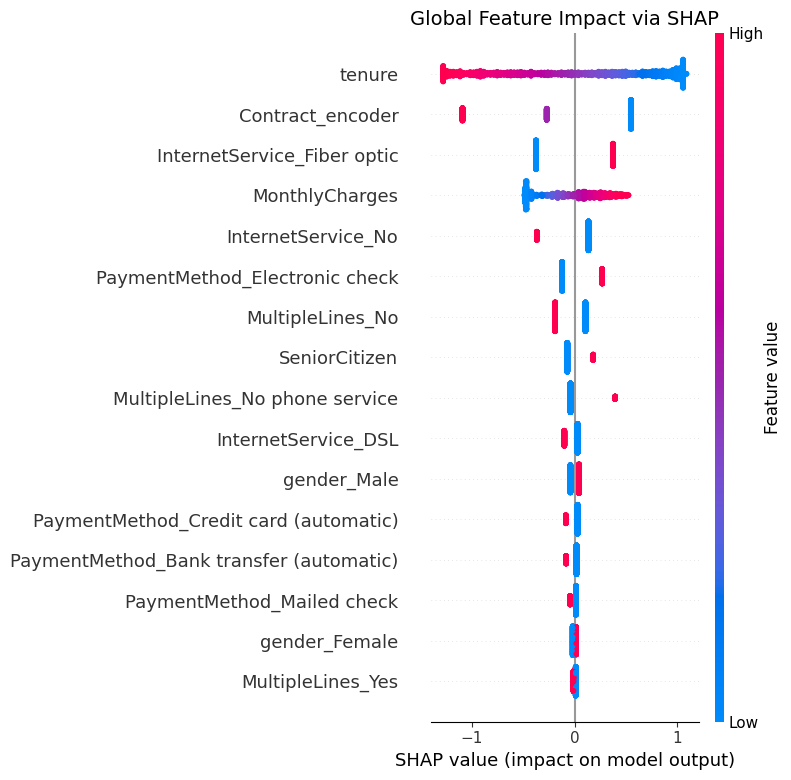


Generating SHAP Waterfall Plot for Customer at index 0...


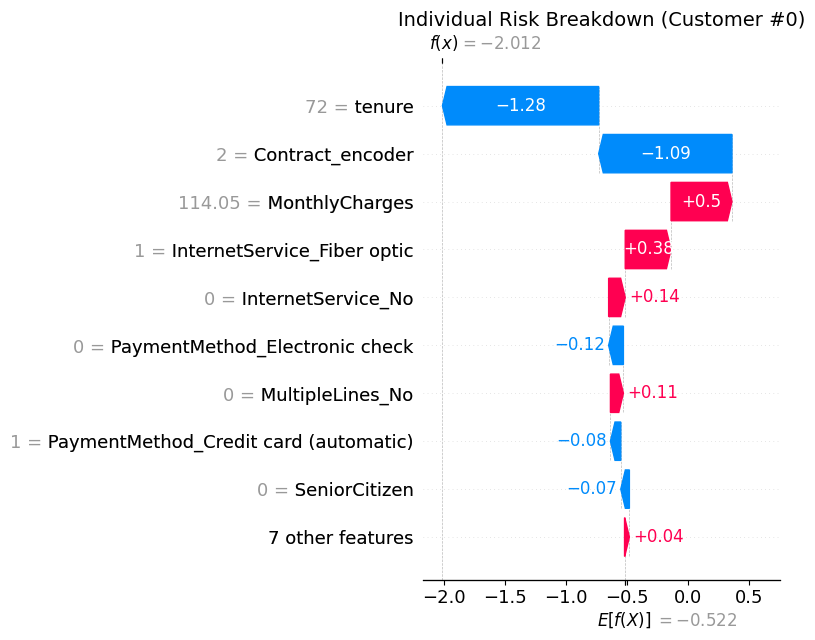

In [ ]:
import shap
import matplotlib.pyplot as plt

# =========================================================================
# EXPLANCE: Initializing SHAP for Logistic Regression
# =========================================================================
# LinearExplainer is optimized specifically for linear and logistic models
explainer = shap.LinearExplainer(clf_balanced, X_train)
shap_values = explainer(X_test)

# 1. Generate the Global Summary Plot
# This shows the distribution of the impacts each feature has on the model output
plt.figure(figsize=(10, 6))
print("Generating Global SHAP Summary Plot...")
shap.summary_plot(shap_values, X_test, show=False)
plt.title("Global Feature Impact via SHAP", fontsize=14)
plt.tight_layout()
plt.show()

# 2. Generate a Local Explanation for a Single High-Risk Customer
# We pick the very first customer in the test set as an example
customer_index = 0

print(f"\nGenerating SHAP Waterfall Plot for Customer at index {customer_index}...")
plt.figure(figsize=(10, 6))
# waterfall plot shows how the features push/pull from the base value
shap.plots.waterfall(shap_values[customer_index], show=False)
plt.title(f"Individual Risk Breakdown (Customer #{customer_index})", fontsize=14)
plt.tight_layout()
plt.show()
